# Decision Tree Lab (Colab / Jupyter Version)
Converted from JupyterLite notebook (piplite removed)

In [1]:
!pip install pandas numpy matplotlib scikit-learn

## Load Dataset

In [4]:
import pandas as pd

df = pd.read_csv("/content/drug200.csv")

df.head()




,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY


## Preprocessing

In [5]:
import numpy as np
from sklearn import preprocessing

X = df[['Age','Sex','BP','Cholesterol','Na_to_K']].copy()

le_sex = preprocessing.LabelEncoder()
X['Sex'] = le_sex.fit_transform(X['Sex'])

le_bp = preprocessing.LabelEncoder()
X['BP'] = le_bp.fit_transform(X['BP'])

le_chol = preprocessing.LabelEncoder()
X['Cholesterol'] = le_chol.fit_transform(X['Cholesterol'])

X = X.values
y = df['Drug']

X[:5]

array([[23.   ,  0.   ,  0.   ,  0.   , 25.355],
       [47.   ,  1.   ,  1.   ,  0.   , 13.093],
       [47.   ,  1.   ,  1.   ,  0.   , 10.114],
       [28.   ,  0.   ,  2.   ,  0.   ,  7.798],
       [61.   ,  0.   ,  1.   ,  0.   , 18.043]])

## Train/Test Split

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=3
)

## Train Decision Tree

In [7]:
from sklearn.tree import DecisionTreeClassifier

drugTree = DecisionTreeClassifier(criterion="entropy", max_depth=4)
drugTree.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=4)

## Prediction

In [8]:
predTree = drugTree.predict(X_test)

print(predTree[:10])
print(y_test[:10].values)

['DrugY' 'drugX' 'drugX' 'drugX' 'drugX' 'drugC' 'DrugY' 'drugA' 'drugB'
 'drugA']
['DrugY' 'drugX' 'drugX' 'drugX' 'drugX' 'drugC' 'DrugY' 'drugA' 'drugB'
 'drugA']


## Accuracy

In [9]:
from sklearn import metrics

print("Decision Tree Accuracy:", metrics.accuracy_score(y_test, predTree))

Decision Tree Accuracy: 0.9833333333333333


## Visualize Decision Tree

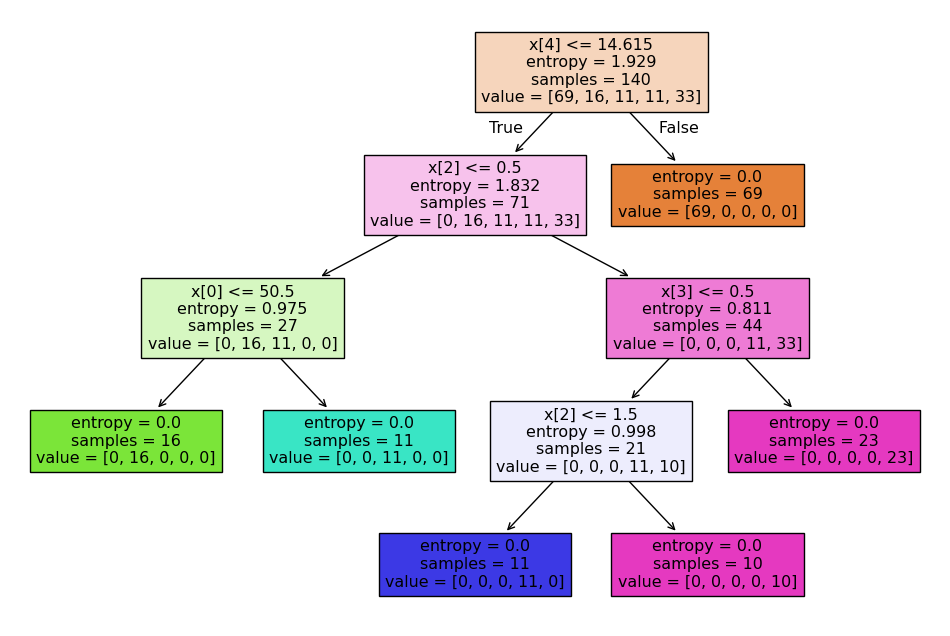

In [10]:
from sklearn import tree
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))
tree.plot_tree(drugTree, filled=True)
plt.show()